In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/raesiow/gi-dataset/atkinson_merged.csv
/kaggle/input/datasets/raesiow/gi-dataset/atkinson_off_fuzzy_matches.csv
/kaggle/input/datasets/raesiow/gi-dataset/gi_table_folds.csv
/kaggle/input/datasets/raesiow/cleaned-off/off_filtered_all_countries.csv


In [3]:
path_gi = "/kaggle/input/datasets/raesiow/gi-dataset/gi_table_folds.csv"  # GI table (6,851 products)
path_off = "/kaggle/input/datasets/raesiow/cleaned-off/off_filtered_all_countries.csv"  # all-countries OFF

gi_table = pd.read_csv(path_gi, dtype={"code": str})  # read GI table, barcode as text
off_all = pd.read_csv(path_off, dtype={"code": str})  # read OFF, barcode as text

print("gi_table", gi_table.shape)  # expect (6851, 16)
print("off_all", off_all.shape)  # expect (376917, 18)
print("barcodes unique in off_all:", off_all["code"].is_unique)  # should be True, so the lookup gives one row per barcode
print("barcodes unique in gi_table:", gi_table["code"].is_unique)  # should be True

cat_lookup = off_all[["code", "pnns_groups_2", "categories_en"]]  # small table: barcode + the two category columns

gi_cat = gi_table.merge(cat_lookup, on="code", how="left")  # attach categories to each GI product (left keeps gi_table rows)

print("gi_cat shape:", gi_cat.shape)  # expect 6851 rows, 18 columns
print("same row order:", (gi_cat["code"].values == gi_table["code"].values).all())  # should be True

# count real gaps (empty cells) and placeholder values
print("pnns_groups_2 empty:", gi_cat["pnns_groups_2"].isna().sum())  # truly missing
print("pnns_groups_2 'unknown':", (gi_cat["pnns_groups_2"].str.lower() == "unknown").sum())  # placeholder
print("categories_en empty:", gi_cat["categories_en"].isna().sum())  # truly missing
print("categories_en 'Null':", (gi_cat["categories_en"].str.lower() == "null").sum())  # placeholder text

n_items = gi_cat["categories_en"].fillna("").str.split(",").apply(len)  # number of comma-separated items per product
print("items per product (categories_en):")  # label
print(n_items.describe())  # min, mean, max number of items

print(gi_cat["pnns_groups_2"].str.lower().value_counts().head(10))  # the 10 most common pnns groups among GI products

gi_table (6851, 16)
off_all (376917, 18)
barcodes unique in off_all: True
barcodes unique in gi_table: True
gi_cat shape: (6851, 18)
same row order: True
pnns_groups_2 empty: 0
pnns_groups_2 'unknown': 613
categories_en empty: 0
categories_en 'Null': 2
items per product (categories_en):
count    6851.000000
mean        6.914757
std         3.054307
min         1.000000
25%         5.000000
50%         7.000000
75%         9.000000
max        23.000000
Name: categories_en, dtype: float64
pnns_groups_2
cereals               1275
unknown                613
breakfast cereals      603
bread                  585
biscuits and cakes     574
sweets                 419
milk and yogurt        362
fruits                 267
legumes                226
chocolate products     181
Name: count, dtype: int64


In [4]:
from sklearn.feature_extraction.text import CountVectorizer  # turns lists of words into 0/1 columns

nut_cols = ["carb_excl_fiber_g", "sugars_g", "fiber_g", "fat_g", "protein_g"]  # the 5 nutrients used by the GI models
x_nut = np.log1p(gi_cat[nut_cols].values)  # log1p of the nutrients, same as before (scaling not needed for GBM)

# variant A: one-hot of pnns_groups_2 (one yes/no column per group)
pnns_clean = gi_cat["pnns_groups_2"].fillna("unknown").str.lower()  # lowercase group names, missing -> unknown
x_pnns = pd.get_dummies(pnns_clean).values.astype(float)  # one column per group, a single 1 in each row
print("variant A columns (groups):", x_pnns.shape[1])  # how many groups

# variant B: 0/1 columns for each category item that appears in at least 30 products
cat_items = gi_cat["categories_en"].fillna("").str.lower()  # lowercase category text
vec = CountVectorizer(tokenizer=lambda s: [t.strip() for t in s.split(",") if t.strip()], token_pattern=None, binary=True, min_df=30, lowercase=False)  # split on commas, keep items in 30+ products, 0/1 values
x_items = vec.fit_transform(cat_items).toarray().astype(float)  # the 0/1 table as an array
print("variant B columns (items):", x_items.shape[1])  # how many items kept
print("example items:", list(vec.get_feature_names_out()[:15]))  # peek at a few item names

# variant C text (embedding is made in the next cell)
print("category texts ready:", len(cat_items))  # expect 6851

# sanity: rows with no kept item at all
print("products with no kept item:", int((x_items.sum(axis=1) == 0).sum()))  # these rows are all zeros in variant B

label = gi_cat["gi"].values  # GI label
weights = gi_cat["food_weight"].values  # each food counts once
folds = gi_cat["fold"].values  # same grouped folds as before
print("folds:", np.unique(folds), "| weights sum:", round(weights.sum(), 1))  # expect folds 0-4 and weights sum 629

variant A columns (groups): 37
variant B columns (items): 207
example items: ['appetizers', 'apple juices', 'aromatic rices', 'bagel breads', 'baked beans in tomato sauce', 'bars', 'bars-covered-with-chocolate', 'basmati rices', 'bee products', 'berries', 'berry jams', 'beverages', 'beverages and beverages preparations', 'biscuits', 'biscuits and cakes']
category texts ready: 6851
products with no kept item: 180
folds: [0 1 2 3 4] | weights sum: 629.0


In [5]:
from sklearn.ensemble import HistGradientBoostingRegressor  # the GBM regressor used before

def run_variant(x_all):  # run 5-fold grouped CV for one feature table
    fold_mae = []  # MAE of each fold
    for k in range(5):  # loop over the 5 folds
        train_mask = folds != k  # rows used for training
        test_mask = folds == k  # rows held out for testing
        model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=42)  # fresh model each fold
        model.fit(x_all[train_mask], label[train_mask], sample_weight=weights[train_mask])  # train with food weights
        pred = model.predict(x_all[test_mask])  # predict held-out fold
        err = np.abs(pred - label[test_mask])  # absolute errors
        fold_mae.append(np.average(err, weights=weights[test_mask]))  # weighted MAE for this fold
    return fold_mae  # list of 5 numbers

results = {}  # store each variant's fold scores
results["0 nutrients only"] = run_variant(x_nut)  # baseline
results["A pnns_groups_2"] = run_variant(np.hstack([x_nut, x_pnns]))  # nutrients + group columns
results["B category items"] = run_variant(np.hstack([x_nut, x_items]))  # nutrients + 0/1 items

table = pd.DataFrame(results).T  # rows = variants, columns = folds
table.columns = ["f0", "f1", "f2", "f3", "f4"]  # name the folds
table["mean"] = table.mean(axis=1)  # mean MAE
table["sd"] = table[["f0", "f1", "f2", "f3", "f4"]].std(axis=1)  # SD across folds (ddof 1)
base = table.loc["0 nutrients only", ["f0", "f1", "f2", "f3", "f4"]].values  # baseline fold scores
table["wins_vs_0"] = [(table.loc[v, ["f0", "f1", "f2", "f3", "f4"]].values < base).sum() for v in table.index]  # folds where lower than baseline
print(table.round(2).to_string())  # print the table

                     f0     f1     f2     f3     f4   mean    sd  wins_vs_0
0 nutrients only  11.71  11.84  11.21  12.24  12.20  11.84  0.42          0
A pnns_groups_2   11.37  11.81  11.08  12.31  11.61  11.64  0.46          4
B category items  11.52  11.60  11.28  12.47  11.36  11.65  0.48          3


In [5]:
import torch  # PyTorch, the neural network library
import torch.nn as nn  # building blocks for networks
from sklearn.preprocessing import StandardScaler  # makes columns have mean 0 and SD 1

def train_mlp_fold(x_train, y_train, w_train, x_test, n_scale=5):  # train one MLP, return predictions for x_test
    torch.manual_seed(42)  # same seed as before
    scaler = StandardScaler()  # scaler for the nutrient columns
    xtr = x_train.copy()  # copy so the original table is not changed
    xte = x_test.copy()  # copy of the test inputs
    xtr[:, :n_scale] = scaler.fit_transform(xtr[:, :n_scale])  # learn scaling from TRAIN rows only, apply to nutrient columns
    xte[:, :n_scale] = scaler.transform(xte[:, :n_scale])  # apply the same scaling to test rows
    mu = np.average(y_train, weights=w_train)  # weighted mean of the training labels
    sd = np.sqrt(np.average((y_train - mu) ** 2, weights=w_train))  # weighted SD of the training labels
    ytr = (y_train - mu) / sd  # scaled labels
    xtr_t = torch.tensor(xtr, dtype=torch.float32)  # inputs as a torch table
    ytr_t = torch.tensor(ytr, dtype=torch.float32).reshape(-1, 1)  # labels as a column
    wtr_t = torch.tensor(w_train, dtype=torch.float32).reshape(-1, 1)  # food weights as a column
    xte_t = torch.tensor(xte, dtype=torch.float32)  # test inputs as a torch table
    net = nn.Sequential(nn.Linear(xtr.shape[1], 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))  # n_inputs -> 32 -> 16 -> 1
    opt = torch.optim.Adam(net.parameters(), lr=0.001, weight_decay=1e-4)  # same optimiser settings as before
    for epoch in range(1000):  # 1000 full-batch epochs
        opt.zero_grad()  # clear old gradients
        loss = (wtr_t * (net(xtr_t) - ytr_t) ** 2).sum() / wtr_t.sum()  # weighted mean squared error
        loss.backward()  # work out how to change the weights
        opt.step()  # change the weights
    net.eval()  # switch to prediction mode
    with torch.no_grad():  # no learning while predicting
        pred = net(xte_t).numpy().ravel()  # predictions in scaled units
    return pred * sd + mu  # convert back to GI units

def run_mlp_variant(x_all):  # 5-fold grouped CV for one feature table
    fold_mae = []  # MAE of each fold
    for k in range(5):  # loop over folds
        tr = folds != k  # training rows
        te = folds == k  # held-out rows
        pred = train_mlp_fold(x_all[tr], label[tr], weights[tr], x_all[te])  # fresh model each fold
        err = np.abs(pred - label[te])  # absolute errors
        fold_mae.append(np.average(err, weights=weights[te]))  # weighted MAE
    return fold_mae  # list of 5 numbers

mlp_results = {}  # store each variant's fold scores
mlp_results["0 nutrients only"] = run_mlp_variant(x_nut)  # baseline MLP
mlp_results["A pnns_groups_2"] = run_mlp_variant(np.hstack([x_nut, x_pnns]))  # nutrients + group columns
mlp_results["B category items"] = run_mlp_variant(np.hstack([x_nut, x_items]))  # nutrients + 0/1 items

mlp_table = pd.DataFrame(mlp_results).T  # rows = variants, columns = folds
mlp_table.columns = ["f0", "f1", "f2", "f3", "f4"]  # name the folds
mlp_table["mean"] = mlp_table.mean(axis=1)  # mean MAE
mlp_table["sd"] = mlp_table[["f0", "f1", "f2", "f3", "f4"]].std(axis=1)  # SD across folds
mlp_base = mlp_table.loc["0 nutrients only", ["f0", "f1", "f2", "f3", "f4"]].values  # baseline fold scores
mlp_table["wins_vs_0"] = [(mlp_table.loc[v, ["f0", "f1", "f2", "f3", "f4"]].values < mlp_base).sum() for v in mlp_table.index]  # folds better than baseline
print(mlp_table.round(2).to_string())  # print the table

                     f0     f1     f2     f3     f4   mean    sd  wins_vs_0
0 nutrients only  12.19  12.89  12.04  12.73  12.25  12.42  0.37          0
A pnns_groups_2   13.09  13.01  12.20  13.70  13.39  13.08  0.56          0
B category items  14.57  13.93  13.90  15.54  15.89  14.77  0.91          0


In [6]:
from sentence_transformers import SentenceTransformer  # MiniLM model library
from sklearn.decomposition import PCA  # compresses 384 numbers to 16

mini = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")  # same MiniLM as before
cat_text = gi_cat["categories_en"].fillna("").str.replace(",", ", ").tolist()  # category text, a space after each comma
cat_emb = mini.encode(cat_text, batch_size=64, show_progress_bar=False)  # 6851 x 384 numbers
print("embeddings:", cat_emb.shape)  # expect (6851, 384)

fold_mae_c = []  # MAE of each fold for variant C
for k in range(5):  # loop over the 5 folds
    tr = folds != k  # training rows
    te = folds == k  # held-out rows
    pca = PCA(n_components=16, random_state=42)  # fresh PCA each fold
    emb_tr = pca.fit_transform(cat_emb[tr])  # learn PCA from TRAIN rows only
    emb_te = pca.transform(cat_emb[te])  # apply the same PCA to test rows
    xtr = np.hstack([x_nut[tr], emb_tr])  # nutrients + 16 embedding columns (train)
    xte = np.hstack([x_nut[te], emb_te])  # same for test
    model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=42)  # same GBM settings
    model.fit(xtr, label[tr], sample_weight=weights[tr])  # train with food weights
    pred = model.predict(xte)  # predict held-out fold
    fold_mae_c.append(np.average(np.abs(pred - label[te]), weights=weights[te]))  # weighted MAE

table.loc["C MiniLM PCA16"] = fold_mae_c + [np.mean(fold_mae_c), np.std(fold_mae_c, ddof=1), 0]  # add a row to the GBM table
base = table.loc["0 nutrients only", ["f0", "f1", "f2", "f3", "f4"]].values  # baseline fold scores
table.loc["C MiniLM PCA16", "wins_vs_0"] = (np.array(fold_mae_c) < base).sum()  # folds better than baseline
print(table.round(2).to_string())  # full GBM table: 0, A, B, C

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

embeddings: (6851, 384)
                     f0     f1     f2     f3     f4   mean    sd  wins_vs_0
0 nutrients only  11.71  11.84  11.21  12.24  12.20  11.84  0.42        0.0
A pnns_groups_2   11.37  11.81  11.08  12.31  11.61  11.64  0.46        4.0
B category items  11.52  11.60  11.28  12.47  11.36  11.65  0.48        3.0
C MiniLM PCA16    10.85  11.10  11.47  12.45  11.24  11.42  0.62        3.0


In [8]:
from sklearn.metrics import balanced_accuracy_score, recall_score  # band metrics

def oof_preds(x_all):  # out-of-fold predictions for one ready-made feature table
    pred_all = np.zeros(len(label))  # slot for each product's held-out prediction
    for k in range(5):  # loop over folds
        tr = folds != k  # training rows
        te = folds == k  # held-out rows
        m = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=42)  # same GBM settings
        m.fit(x_all[tr], label[tr], sample_weight=weights[tr])  # train with food weights
        pred_all[te] = m.predict(x_all[te])  # predict held-out fold
    return pred_all  # one prediction per product

def oof_preds_c():  # out-of-fold predictions for variant C (PCA fitted inside each fold)
    pred_all = np.zeros(len(label))  # slot for each product's held-out prediction
    for k in range(5):  # loop over folds
        tr = folds != k  # training rows
        te = folds == k  # held-out rows
        pca = PCA(n_components=16, random_state=42)  # fresh PCA each fold
        emb_tr = pca.fit_transform(cat_emb[tr])  # learn PCA from TRAIN rows only
        emb_te = pca.transform(cat_emb[te])  # apply the same PCA to test rows
        m = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=42)  # same GBM settings
        m.fit(np.hstack([x_nut[tr], emb_tr]), label[tr], sample_weight=weights[tr])  # train with food weights
        pred_all[te] = m.predict(np.hstack([x_nut[te], emb_te]))  # predict held-out fold
    return pred_all  # one prediction per product

def to_band(g):  # same bands as before: <=55 low, 56-69 medium, >=70 high
    return pd.cut(g, bins=[-np.inf, 55, 69, np.inf], labels=["low", "medium", "high"])  # band labels

true_band = to_band(label)  # true bands
preds = {  # all three variants' out-of-fold predictions
    "0": oof_preds(x_nut),  # nutrients only
    "A": oof_preds(np.hstack([x_nut, x_pnns])),  # nutrients + pnns_groups_2
    "C": oof_preds_c(),  # nutrients + MiniLM PCA16
}
for name, p in preds.items():  # loop over the three variants
    pb = to_band(p)  # predicted bands
    bal = balanced_accuracy_score(true_band, pb, sample_weight=weights)  # balanced accuracy, food-weighted
    hi = recall_score(true_band == "high", pb == "high", sample_weight=weights)  # share of truly high foods predicted high
    print("variant", name, "| balanced acc:", round(bal, 3), "| high-GI recall:", round(hi, 3), "| SD of predictions:", round(p.std(), 1))  # summary
    gi_cat["pred_" + name] = p  # keep predictions for the next check

# sauce-like products: predicted GI, variants 0, A and C
sauce_like = gi_cat["pnns_groups_2"].str.lower().isin(["dressings and sauces", "pickles", "fats"])  # sauce-like groups in the GI table
print("sauce-like products in GI table:", int(sauce_like.sum()))  # how many there are
print(gi_cat.loc[sauce_like, ["pred_0", "pred_A", "pred_C"]].describe().round(1))  # mean/min/max predicted GI

variant 0 | balanced acc: 0.461 | high-GI recall: 0.172 | SD of predictions: 11.2
variant A | balanced acc: 0.485 | high-GI recall: 0.207 | SD of predictions: 11.4
variant C | balanced acc: 0.481 | high-GI recall: 0.202 | SD of predictions: 11.8
sauce-like products in GI table: 99
       pred_0  pred_A  pred_C
count    99.0    99.0    99.0
mean     54.4    50.7    48.0
std       9.9     8.6     9.6
min      24.9    28.7    26.0
25%      51.0    43.9    42.2
50%      55.9    51.3    43.4
75%      61.2    56.5    56.5
max      77.3    69.6    72.2


In [7]:
save_cols = ["code", "gi", "food_weight", "fold", "pred_0", "pred_A"]  # barcode, true GI, weight, fold, GBM nutrients-only, GBM + category (app model)
gi_cat[save_cols].to_csv("/kaggle/working/gi_gbm_oof_preds.csv", index=False)  # save to the output folder

for k in range(5):  # check each fold's MAE for the app model
    s = gi_cat[gi_cat["fold"] == k]  # rows of this fold
    print(k, round(np.average((s["gi"] - s["pred_A"]).abs(), weights=s["food_weight"]), 2))  # weighted MAE

0 11.37
1 11.81
2 11.08
3 12.31
4 11.61


In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier  # GBM for classes
from sklearn.metrics import precision_score  # share of "high" predictions that are right

y_band = true_band.codes  # bands as numbers: 0 low, 1 medium, 2 high

def band_oof(x_all):  # out-of-fold band predictions from a classifier
    pred_all = np.zeros(len(label), dtype=int)  # slot for each product's predicted band
    for k in range(5):  # loop over folds
        tr = folds != k  # training rows
        te = folds == k  # held-out rows
        class_total = np.array([weights[tr][y_band[tr] == c].sum() for c in range(3)])  # total food weight per band
        class_w = class_total.sum() / (3 * class_total)  # balanced weight: rare bands count more
        sw = weights[tr] * class_w[y_band[tr]]  # food weight x class weight
        m = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=42)  # fresh model each fold
        m.fit(x_all[tr], y_band[tr], sample_weight=sw)  # train
        pred_all[te] = m.predict(x_all[te])  # predict held-out fold
    return pred_all  # one band per product

def fold_bal(pred_codes):  # balanced accuracy per fold
    return [balanced_accuracy_score(y_band[folds == k], pred_codes[folds == k], sample_weight=weights[folds == k]) for k in range(5)]  # list of 5

rows = {}  # collect results
for name, x_all in [("0", x_nut), ("A", np.hstack([x_nut, x_pnns]))]:  # two feature sets
    reg_codes = to_band(preds[name]).codes  # bands from the regression predictions
    clf_codes = band_oof(x_all)  # bands from the classifier
    for label_name, codes in [("regress-then-bin " + name, reg_codes), ("classifier " + name, clf_codes)]:  # both methods
        fb = fold_bal(codes)  # per-fold balanced accuracy
        rec = recall_score(y_band == 2, codes == 2, sample_weight=weights)  # high recall
        prec = precision_score(y_band == 2, codes == 2, sample_weight=weights)  # high precision
        rows[label_name] = fb + [np.mean(fb), np.std(fb, ddof=1), rec, prec]  # one table row

band_table = pd.DataFrame(rows).T  # rows = methods
band_table.columns = ["f0", "f1", "f2", "f3", "f4", "mean bal acc", "sd", "high recall", "high precision"]  # names
for name in ["0", "A"]:  # wins of classifier over regress-then-bin
    band_table.loc["classifier " + name, "wins"] = (band_table.loc["classifier " + name, ["f0", "f1", "f2", "f3", "f4"]].values.astype(float) > band_table.loc["regress-then-bin " + name, ["f0", "f1", "f2", "f3", "f4"]].values.astype(float)).sum()  # folds where classifier is better
print(band_table.round(3).to_string())  # print the table

                       f0     f1     f2     f3     f4  mean bal acc     sd  high recall  high precision  wins
regress-then-bin 0  0.482  0.475  0.476  0.404  0.473         0.462  0.033        0.172           0.459   NaN
classifier 0        0.494  0.528  0.483  0.482  0.522         0.502  0.022        0.449           0.394   5.0
regress-then-bin A  0.487  0.477  0.503  0.441  0.515         0.485  0.028        0.207           0.472   NaN
classifier A        0.466  0.493  0.486  0.479  0.543         0.493  0.029        0.451           0.368   3.0


In [10]:
# label should be the raw GI numbers
print("label: min", label.min().round(1), "mean", label.mean().round(1), "max", label.max().round(1))  # expect about 3, 52.6, 120
# x_pnns should have one column per category
print("x_pnns shape:", x_pnns.shape)  # expect 6851 rows and 37 columns

label: min 3.0 mean 52.6 max 120.0
x_pnns shape: (6851, 37)


{'gi_table_folds.csv': '/kaggle/input/datasets/raesiow/gi-dataset/gi_table_folds.csv', 'off_filtered_all_countries.csv': '/kaggle/input/datasets/raesiow/cleaned-off/off_filtered_all_countries.csv'}
6851 rows, 37 categories
MAE per fold: [11.37 11.81 11.08 12.31 11.61] mean 11.64
GI 85+: 112 products, average prediction 62.5 | food-weighted 62.9
GI <30: 669 products, average prediction 38.3 | food-weighted 43.7


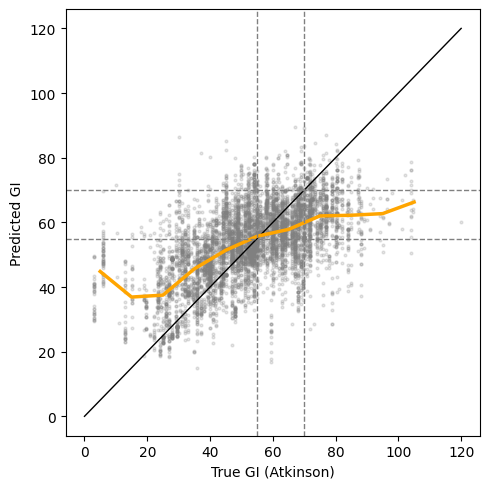

In [2]:
import os                                             # for searching folders
import numpy as np                                    # number tools
import pandas as pd                                   # tables
import matplotlib.pyplot as plt                       # plotting
from sklearn.ensemble import HistGradientBoostingRegressor  # the GBM regressor

# find the two files anywhere in the inputs
paths = {}                                            # empty dictionary for file paths
for root, dirs, files in os.walk("/kaggle/input"):    # walk through every input folder
    for f in files:                                   # look at each file name
        if f in ["gi_table_folds.csv", "off_filtered_all_countries.csv"]:  # the two we need
            paths[f] = os.path.join(root, f)          # remember where it is
print(paths)                                          # should show both files

gi = pd.read_csv(paths["gi_table_folds.csv"], dtype={"code": str})   # GI table, 6,851 rows
off = pd.read_csv(paths["off_filtered_all_countries.csv"],
                  usecols=["code", "pnns_groups_2"], dtype={"code": str})  # only barcode + category
off = off.drop_duplicates("code")                     # one row per barcode, to be safe
gi = gi.merge(off, on="code", how="left")             # add the category to each GI product
gi["pnns_groups_2"] = gi["pnns_groups_2"].fillna("unknown")  # missing category -> "unknown"
print(len(gi), "rows,", gi["pnns_groups_2"].nunique(), "categories")  # expect 6851 rows, about 37

nutrients = ["carb_excl_fiber_g", "sugars_g", "fiber_g", "fat_g", "protein_g"]  # the five nutrients
x_nut = np.log1p(gi[nutrients].clip(lower=0))         # clip at 0, then log, as in the app model
x_cat = pd.get_dummies(gi["pnns_groups_2"], dtype=float)  # one column per category
x = pd.concat([x_nut, x_cat], axis=1).values          # all inputs together
y = gi["gi"].values                                   # true GI
w = gi["food_weight"].values                          # food weights

pred = np.zeros(len(gi))                              # space for out-of-fold predictions
fold_mae = []                                         # MAE of each fold
for k in sorted(gi["fold"].unique()):                 # loop over the five folds
    test = (gi["fold"] == k).values                   # rows in this test fold
    model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=42)  # same settings
    model.fit(x[~test], y[~test], sample_weight=w[~test])  # train on the other four folds
    pred[test] = model.predict(x[test])               # predict the test fold
    err = np.abs(pred[test] - y[test])                # absolute errors
    fold_mae.append(np.average(err, weights=w[test])) # weighted MAE for this fold
print("MAE per fold:", np.round(fold_mae, 2), "mean", round(np.mean(fold_mae), 2))  # sanity: about 11.6

high = y >= 85                                        # true GI 85 or more
low = y < 30                                          # true GI below 30
print("GI 85+:", high.sum(), "products, average prediction", round(pred[high].mean(), 1),
      "| food-weighted", round(np.average(pred[high], weights=w[high]), 1))
print("GI <30:", low.sum(), "products, average prediction", round(pred[low].mean(), 1),
      "| food-weighted", round(np.average(pred[low], weights=w[low]), 1))

# redraw the scatter plot
bins = np.arange(0, 125, 10)                          # true GI ranges of 10
mid, avg = [], []                                     # bin middles and average predictions
for a, b in zip(bins[:-1], bins[1:]):                 # each range
    inside = (y >= a) & (y < b)                       # products in this range
    if inside.sum() >= 10:                            # skip nearly empty ranges
        mid.append((a + b) / 2)                       # middle of the range
        avg.append(pred[inside].mean())               # average prediction in the range
plt.figure(figsize=(5, 5))                            # square figure
plt.scatter(y, pred, s=4, alpha=0.2, color="grey")    # one dot per product
plt.plot([0, 120], [0, 120], color="black", lw=1)     # diagonal = perfect prediction
plt.plot(mid, avg, color="orange", lw=2.5)            # average prediction per range
for c in [55, 70]:                                    # band cut-offs
    plt.axvline(c, ls="--", color="grey", lw=1)       # vertical dashed line
    plt.axhline(c, ls="--", color="grey", lw=1)       # horizontal dashed line
plt.xlabel("True GI (Atkinson)")                      # x-axis label
plt.ylabel("Predicted GI")                            # y-axis label
plt.tight_layout()                                    # tidy spacing
plt.savefig("/kaggle/working/gi_scatter_gbm.png", dpi=200)  # save for Overleaf
plt.show()                                            # show it